# Завдання 6. Порівняння дифузійної моделі з простими способами

**Пункт 6 ТЗ.** Порівняти дифузійну модель із простими способами оцінювання близькості (довжина найкоротшого шляху, кількість спільних сусідів, вибір вузлів у межах k кроків від вузла запиту) за якістю ранжування (precision@k, nDCG, MRR) на графах з відомими релевантними вузлами, а також за кількістю вузлів, які потрібно відібрати, щоб охопити всі релевантні.

**Методологія:**
- **Налаштування окремо від оцінювання.** Варіант дифузії (модель, параметр, нормування, сценарій ваг) обираємо на окремих даних: на SBM — на графах з іншим seed, на MetaQA — на питаннях train+dev. Звітуємо на нових даних: SBM з основним seed, MetaQA test. Обраний варіант порівнюємо з базовими методами один на один. Таблиця всіх варіантів — лише «верхня межа».
- **Нічиї базових методів:** три межі — random, pessimistic, optimistic.
- **Вузол запиту** виключено з ранжування і з правильних відповідей.
- **Розмір вибірки для повного охоплення** — мінімальна кількість верхніх вузлів, що містить усі правильні відповіді. Це аналог розміру контексту, який треба передати LLM.
- **Порівняння з k-hop при однаковому бюджеті** (головне для диплома). Для кожного питання і k = 1, 2, 3 беремо N = розмір k-околу вузла запиту і порівнюємо повноту k-hop (частку відповідей у k-околі) з повнотою топ-N дифузії.

In [1]:
from pathlib import Path
from collections import defaultdict
import time
import networkx as nx
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from reldiff.api import rank
from reldiff import graphs as G
from reldiff import metaqa as MQ
from reldiff import metrics as M

FIG = Path("../figures"); RES = Path("../results")
pd.set_option("display.float_format", "{:.3f}".format); pd.set_option("display.width", 250); pd.set_option("display.max_rows", 200)
TIES = ["random", "pessimistic", "optimistic"]
KS = (1, 5, 10)

def evaluate(scores, relevant, seeds, ties="random", ks=KS):
    out = M.evaluate(scores, relevant, ks=ks, seeds=seeds, ties=ties, seed=0)
    out["RR"] = out.pop("RR"); return out

def recall_at(scores, relevant, seeds, n, ties="random"):
    order = M.ranking(scores, relevant=set(relevant), seeds=seeds, ties=ties, seed=0)
    rel = set(relevant) - set(seeds)
    return len(rel & set(order[:n])) / len(rel)

T005_MQ = 7.89   # t*(0.05) для MetaQA з п. 3

## Завдання 6.1. SBM: правильні відповіді — вузли спільноти запиту

5 спільнот по 200 вузлів, p_in = 0.05 (внутрішній степінь ≈ 10). p_out ∈ {0.001, 0.005, 0.0075, 0.01, 0.02}: зовнішній степінь ≈ 0.8, 4, 6, 8 і 16. p_out = 0.02 — контроль: зовнішній степінь більший за внутрішній, спільноти майже невиявні, тож усі методи мають бути близькі до випадкових. Випадкове ранжування дає P@k ≈ 199/999 ≈ 0.2.

На кожному графі 50 запитів. Налаштування — на окремих графах (seed + 100, 30 запитів).

In [2]:
POUTS = [0.001, 0.005, 0.0075, 0.01, 0.02]
SBM_MODELS = [("PPR", "α=0.05", dict(method="ppr", alpha=0.05)), ("PPR", "α=0.15", dict(method="ppr", alpha=0.15)),
              ("PPR", "α=0.5", dict(method="ppr", alpha=0.5)), ("теплове ядро", "t=7.0", dict(method="heat", t=7.0)),
              ("теплове ядро", "t=5.67", dict(method="heat", t=0.85 / 0.15)), ("теплове ядро", "t=1", dict(method="heat", t=1.0))]
NORMS = [(None, "сирі"), ("sqrt_degree", "π/√d"), ("degree", "π/d")]
SBM_BASE = [("найкор. шлях", dict(method="shortest_path")), ("схожість Σ|N(v)∩N(q)|", dict(method="common_neighbors")),
            ("k-hop, k=1", dict(method="k_hop", hops=1)), ("k-hop, k=2", dict(method="k_hop", hops=2)),
            ("k-hop, k=3", dict(method="k_hop", hops=3))]

def sbm_run(seed_g, n_q, seed_q, with_base=True):
    rows, budget = [], []
    for po in POUTS:
        g = G.sbm([200] * 5, 0.05, po, seed=seed_g)
        comm = G.communities(g)
        r = np.random.default_rng(seed_q); nodes = list(g.nodes())
        for q in [nodes[i] for i in r.choice(len(nodes), n_q, replace=False)]:
            rel = comm[g.nodes[q]["community"]] - {q}
            dist = nx.single_source_shortest_path_length(g, q)
            diff_scores = {}
            for model, pname, kw in SBM_MODELS:
                for norm, nl in NORMS:
                    sc = rank(g, q, normalize=norm, **kw)
                    diff_scores[(model, pname, nl)] = sc
                    rows.append(dict(p_out=po, метод=f"{model}, {pname}", нормування=nl, нічиї="random",
                                     **evaluate(sc, rel, [q], ks=(10, 50))))
            if with_base:
                for bname, kw in SBM_BASE:
                    sc = rank(g, q, **kw)
                    for ties in TIES:
                        rows.append(dict(p_out=po, метод=bname, нормування="", нічиї=ties,
                                         **evaluate(sc, rel, [q], ties=ties, ks=(10, 50))))
                for k in (1, 2, 3):
                    ball = [v for v, d in dist.items() if 0 < d <= k]
                    budget.append(dict(p_out=po, k=k, N=len(ball), q=q, rel=rel, ball=set(ball), scores=diff_scores))
    return pd.DataFrame(rows), budget

t0 = time.perf_counter()
tune_sbm, _ = sbm_run(seed_g=106, n_q=30, seed_q=1, with_base=False)
tune_sbm_m = tune_sbm.groupby(["метод", "нормування"])["nDCG@50"].mean().sort_values(ascending=False)
SBM_CHOICE = tune_sbm_m.index[0]
print(f"Налаштування SBM ({time.perf_counter() - t0:.0f} с): найкращий за середнім nDCG@50 на окремих графах: {SBM_CHOICE} "
      f"({tune_sbm_m.iloc[0]:.3f}); далі {list(tune_sbm_m.index[1:3])}")
sbm, sbm_budget = sbm_run(seed_g=6, n_q=50, seed_q=2)
sbm["охоплення"] = sbm["coverage"].replace(np.inf, np.nan)
sbm_m = sbm.groupby(["p_out", "метод", "нормування", "нічиї"], sort=False).agg(
    **{c: (c, "mean") for c in ["P@10", "P@50", "nDCG@10", "nDCG@50", "RR"]},
    охоплення_медіана=("coverage", "median"), частка_охоплених=("coverage", lambda x: np.isfinite(x).mean())).reset_index()
sbm_m.to_csv(RES / "06_sbm_usi_varianty.csv", index=False)
print(f"Основний прогін SBM: {time.perf_counter() - t0:.0f} с")

Налаштування SBM (146 с): найкращий за середнім nDCG@50 на окремих графах: ('теплове ядро, t=7.0', 'π/√d') (0.722); далі [('теплове ядро, t=7.0', 'π/d'), ('теплове ядро, t=5.67', 'π/√d')]


Основний прогін SBM: 400 с


P@10                         nDCG@50                         охоплення_медіана                                
p_out                               0.001 0.005 0.007 0.010 0.020   0.001 0.005 0.007 0.010 0.020             0.001   0.005   0.007   0.010   0.020
варіант                                                                                                                                            
ОБРАНИЙ: теплове ядро, t=7.0, π/√d  0.982 0.896 0.826 0.692 0.434   0.991 0.899 0.775 0.585 0.362           201.000 772.000 975.500 991.500 996.000
найкор. шлях [random]               0.890 0.760 0.620 0.528 0.400   0.844 0.613 0.493 0.417 0.325           784.000 963.500 977.000 988.000 994.000
найкор. шлях [pessimistic]          0.810 0.628 0.406 0.152 0.000   0.648 0.253 0.216 0.198 0.179           869.500 999.000 997.000 996.000 999.000
найкор. шлях [optimistic]           0.950 0.922 0.886 0.874 0.902   0.972 0.924 0.880 0.815 0.697           343.500 802.500 601.500 425.000 598.000
схожість Σ|N(v)∩N(q)| [random]      0.954 0.856 0.682 0.556 0.336   0.873 0.688 0.574 0.462 0.298           993.000 994.000 995.000 994.000 994.500
схожість Σ|N(v)∩N(q)| [pessimistic] 0.882 0.638 0.420 0.368 0.182   0.725 0.471 0.406 0.318 0.187           999.000 999.000 999.000 999.000 999.000
схожість Σ|N(v)∩N(q)| [optimistic]  0.994 0.960 0.878 0.778 0.570   0.984 0.923 0.806 0.673 0.522           214.500 276.000 329.500 398.000 588.000
k-hop, k=1 [random]                 0.814 0.702 0.590 0.456 0.348   0.326 0.316 0.286 0.279 0.256               inf     inf     inf     inf     inf
k-hop, k=1 [pessimistic]            0.806 0.628 0.406 0.152 0.000   0.293 0.252 0.216 0.198 0.179               inf     inf     inf     inf     inf
k-hop, k=1 [optimistic]             0.852 0.902 0.878 0.874 0.902   0.334 0.351 0.342 0.348 0.357               inf     inf     inf     inf     inf
k-hop, k=2 [random]                 0.876 0.734 0.636 0.554 0.416   0.848 0.598 0.484 0.424 0.336               inf     inf     inf     inf     inf
k-hop, k=2 [pessimistic]            0.810 0.628 0.406 0.152 0.000   0.648 0.253 0.216 0.198 0.179               inf     inf     inf     inf     inf
k-hop, k=2 [optimistic]             0.950 0.922 0.886 0.874 0.902   0.972 0.924 0.880 0.815 0.697               inf     inf     inf     inf     inf
k-hop, k=3 [random]                 0.902 0.738 0.636 0.530 0.400   0.845 0.594 0.507 0.422 0.325               inf     inf     inf 991.000 994.000
k-hop, k=3 [pessimistic]            0.810 0.628 0.406 0.152 0.000   0.648 0.253 0.216 0.198 0.179               inf     inf     inf 996.000 999.000
k-hop, k=3 [optimistic]             0.950 0.922 0.886 0.874 0.902   0.972 0.924 0.880 0.815 0.697               inf     inf     inf 425.000 598.000

Верхня межа дифузії (найкращий з 18 варіантів для кожного p_out):


,P@10,nDCG@50
p_out,,
0.001,0.990,0.992
0.005,0.900,0.899
0.007,0.826,0.775
0.010,0.692,0.590
0.020,0.446,0.378


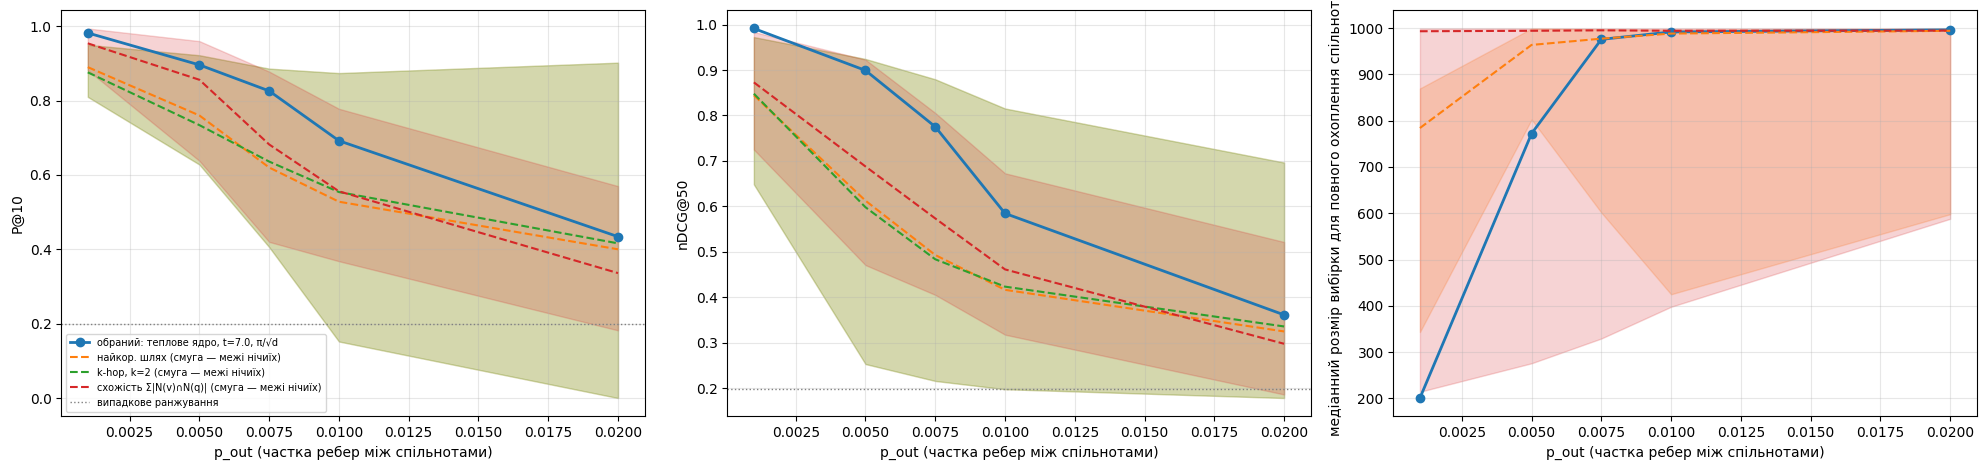

In [3]:
sel = sbm_m[((sbm_m["метод"] == SBM_CHOICE[0]) & (sbm_m["нормування"] == SBM_CHOICE[1])) | (sbm_m["нормування"] == "")]
sel = sel.assign(варіант=lambda d: np.where(d["нормування"] == "", d["метод"] + " [" + d["нічиї"] + "]",
                                             "ОБРАНИЙ: " + d["метод"] + ", " + d["нормування"]))
tab = sel.pivot_table(index="варіант", columns="p_out", values=["P@10", "nDCG@50", "охоплення_медіана"], sort=False)
tab.to_csv(RES / "06_sbm_obranyi_vs_bazovi.csv")
display(tab)
ub = sbm_m[sbm_m["нормування"] != ""].groupby("p_out")[["P@10", "nDCG@50"]].max()
print("Верхня межа дифузії (найкращий з 18 варіантів для кожного p_out):"); display(ub)

fig, axs = plt.subplots(1, 3, figsize=(20, 4.8))
for ax, col, lab in zip(axs, ("P@10", "nDCG@50", "охоплення_медіана"),
                        ("P@10", "nDCG@50", "медіанний розмір вибірки для повного охоплення спільноти")):
    s0 = sel[sel["нормування"] != ""].set_index("p_out")[col]
    ax.plot(POUTS, s0.reindex(POUTS), "o-", lw=2, color="C0", label=f"обраний: {SBM_CHOICE[0]}, {SBM_CHOICE[1]}")
    for i, bname in enumerate(["найкор. шлях", "k-hop, k=2", "схожість Σ|N(v)∩N(q)|"]):
        b = sel[sel["метод"] == bname].set_index(["p_out", "нічиї"])[col].unstack()
        ax.fill_between(POUTS, b["pessimistic"].reindex(POUTS), b["optimistic"].reindex(POUTS), color=f"C{i + 1}", alpha=0.2)
        ax.plot(POUTS, b["random"].reindex(POUTS), "--", color=f"C{i + 1}", label=f"{bname} (смуга — межі нічиїх)")
    if col != "охоплення_медіана":
        ax.axhline(199 / 999, color="gray", ls=":", lw=1, label="випадкове ранжування")
    ax.set_xlabel("p_out (частка ребер між спільнотами)"); ax.set_ylabel(lab); ax.grid(alpha=0.3)
axs[0].legend(fontsize=7)
plt.tight_layout(); plt.savefig(FIG / "06_sbm_yakist.png", dpi=200); plt.show()

### SBM: однаковий бюджет з k-hop

Для кожного запиту і k = 1, 2, 3: N = розмір k-околу. Повнота k-hop — частка вузлів своєї спільноти в k-околі. Повнота дифузії — частка своєї спільноти серед її топ-N.

In [4]:
rows = []
for b in sbm_budget:
    sc = b["scores"][SBM_CHOICE[0].split(", ")[0], SBM_CHOICE[0].split(", ")[1], SBM_CHOICE[1]]
    rec_k = len(b["rel"] & b["ball"]) / len(b["rel"])
    rows.append(dict(p_out=b["p_out"], k=b["k"], N=b["N"], повнота_khop=rec_k,
                     повнота_дифузії=recall_at(sc, b["rel"], [b["q"]], b["N"])))
sbm_bud = pd.DataFrame(rows)
sbm_bud_m = sbm_bud.groupby(["p_out", "k"]).agg(N_медіана=("N", "median"), повнота_khop=("повнота_khop", "mean"),
                                                повнота_дифузії=("повнота_дифузії", "mean")).reset_index()
sbm_bud_m.to_csv(RES / "06_sbm_byudzhet_khop.csv", index=False)
display(sbm_bud_m.pivot_table(index="p_out", columns="k", values=["N_медіана", "повнота_khop", "повнота_дифузії"]))

N_медіана                 повнота_khop             повнота_дифузії            
k             1       2       3            1     2     3               1     2     3
p_out                                                                               
0.001    10.000  99.500 395.000        0.047 0.406 0.974           0.051 0.492 1.000
0.005    14.000 179.500 857.000        0.051 0.441 0.989           0.056 0.684 0.997
0.007    15.000 223.500 955.500        0.049 0.440 0.992           0.051 0.592 0.990
0.010    20.000 310.000 993.000        0.050 0.488 0.997           0.052 0.529 0.996
0.020    26.000 521.500 999.000        0.052 0.593 1.000           0.052 0.568 1.000

## Завдання 6.2. MetaQA: питання 1/2/3-hop

Стратифікована вибірка, seed = 0:
- налаштування (36 варіантів) — до 20 питань на qtype з train+dev;
- оцінювання обраного варіанта і базових методів — до 100 питань на qtype з test;
- «верхня межа» (усі 36 варіантів на test) — підвибірка до 15 на qtype з test-вибірки. Рідкісні qtype (movie_to_imdbvotes, movie_to_imdbrating) окремо не аналізуємо і з макросереднього виключаємо. Основний критерій — відповіді, перераховані на підграфі (етап 4).

**Варіанти дифузії:**
- PPR (α ∈ {0.05, 0.15, 0.5}) і теплове ядро (t ∈ {7.89 = t*(0.05), 5.67, 1});
- нормування: сирі оцінки, π/√d, π/d, IDF-граф (β = 0.5 і 1);
- сценарій ваг «змістовні зв'язки важчі» (r = 4) з п. 4.

Разом 36 варіантів. **Базові методи:** найкоротший шлях, схожість Σ|N(v) ∩ N(q)|, k-hop при k = 1, 2, 3.

Через великий обсяг питання обробляємо групами за вузлом запиту: усі варіанти для одного вузла рахуємо один раз і оцінюємо всі його питання.

In [5]:
g, q_all, _ = MQ.load_processed("../data/metaqa", 500, 0)
edges = pd.read_csv("../data/metaqa/processed/movies500_seed0/subgraph_edges.csv", dtype=str, keep_default_na=False)
deg_un = dict(g.degree())
def idf_graph(beta):
    h = nx.MultiGraph(); h.add_nodes_from(g.nodes(data=True))
    for s_, r_, o_ in edges.itertuples(index=False, name=None):
        h.add_edge(s_, o_, type=r_, weight=deg_un[o_] ** (-beta))
    return h
RELS = sorted(MQ.RELATION_KIND); PERSON = {"starred_actors", "directed_by", "written_by"}
VARIANTS = [("сирі", g, dict()), ("π/√d", g, dict(normalize="sqrt_degree")), ("π/d", g, dict(normalize="degree")),
            ("IDF β=0.5", idf_graph(0.5), dict()), ("IDF β=1", idf_graph(1.0), dict()),
            ("змістовні r=4", g, dict(type_weights={r: (4.0 if r in PERSON else 1.0) for r in RELS}))]
MQ_MODELS = [("PPR", "α=0.05", dict(method="ppr", alpha=0.05)), ("PPR", "α=0.15", dict(method="ppr", alpha=0.15)),
             ("PPR", "α=0.5", dict(method="ppr", alpha=0.5)), ("теплове ядро", f"t={T005_MQ}", dict(method="heat", t=T005_MQ)),
             ("теплове ядро", "t=5.67", dict(method="heat", t=0.85 / 0.15)), ("теплове ядро", "t=1", dict(method="heat", t=1.0))]
RARE = {"movie_to_imdbvotes", "movie_to_imdbrating"}

rng = np.random.default_rng(0)
q_all = q_all[~q_all["qtype"].isin(RARE)].copy()
q_all["частина"] = np.where(q_all["split"] == "test", "test", "train+dev")
def strat(df, n):
    return pd.concat([grp.iloc[np.sort(rng.choice(len(grp), min(n, len(grp)), replace=False))]
                      for _, grp in df.groupby("qtype", sort=True)])
TUNE = strat(q_all[q_all["частина"] == "train+dev"], 20)     # налаштування: до 20 на qtype (36 варіантів)
TEST = strat(q_all[q_all["частина"] == "test"], 100)          # оцінювання обраного варіанта: до 100 на qtype
TEST_UB = strat(TEST, 15)                                      # «верхня межа» (усі 36 варіантів): до 15 на qtype
print(f"Питань: налаштування {len(TUNE)} (вузлів запиту {TUNE.topic.nunique()}), test {len(TEST)} (вузлів {TEST.topic.nunique()}), "
      f"підвибірка test для верхньої межі {len(TEST_UB)}; "
      f"qtype: {TEST.qtype.nunique()}")
print(TEST.groupby("hop").size().to_dict())

ANS_KIND = {"movie": {"movie"}, "actor": {"actor"}, "director": {"director"}, "writer": {"writer"}, "genre": {"genre"},
            "year": {"year"}, "language": {"language"}, "tags": {"tag"}, "tag": {"tag"}}
kinds = {v: set(k) for v, k in g.nodes(data="kinds")}

def run_questions(Q, with_base, budget=False, variants_only=None):
    rows, brows = [], []
    for topic, grp in Q.groupby("topic", sort=False):
        dist = nx.single_source_shortest_path_length(g, topic)
        scores = {}
        for model, pname, mkw in MQ_MODELS:
            for vname, gg, vkw in VARIANTS:
                key = (f"{model}, {pname}", vname)
                if variants_only is not None and key not in variants_only:
                    continue
                scores[key] = rank(gg, topic, **mkw, **vkw)
        base = {}
        if with_base:
            for bname, kw in (("найкор. шлях", dict(method="shortest_path")), ("схожість Σ|N(v)∩N(q)|", dict(method="common_neighbors")),
                              ("k-hop, k=1", dict(method="k_hop", hops=1)), ("k-hop, k=2", dict(method="k_hop", hops=2)),
                              ("k-hop, k=3", dict(method="k_hop", hops=3))):
                base[bname] = rank(g, topic, **kw)
        for qq in grp.itertuples():
            rel = set(qq.answers) - {topic}
            if not rel: continue
            meta = dict(hop=qq.hop, qtype=qq.qtype, topic=topic, n_answers=len(rel),
                        макс_відстань_відповіді=max(dist.get(a, np.inf) for a in rel))
            for (meth, vname), sc in scores.items():
                rows.append(dict(**meta, метод=meth, варіант=vname, нічиї="random", фільтр="ні", **evaluate(sc, rel, [topic])))
            for bname, sc in base.items():
                for ties in TIES:
                    rows.append(dict(**meta, метод=bname, варіант="", нічиї=ties, фільтр="ні", **evaluate(sc, rel, [topic], ties=ties)))
            if budget:
                last = qq.qtype.split("_to_")[-1]; allowed = ANS_KIND.get(last, set())
                for (meth, vname), sc in scores.items():
                    for k in (1, 2, 3):
                        N = sum(1 for v, d in dist.items() if 0 < d <= k)
                        brows.append(dict(**meta, метод=meth, варіант=vname, k=k, N=N,
                                          повнота_khop=len([a for a in rel if dist.get(a, np.inf) <= k]) / len(rel),
                                          повнота_дифузії=recall_at(sc, rel, [topic], N)))
                    # додатково: фільтр за типом відповіді
                    scf = sc.copy(); scf[[v for v in scf.index if not (kinds[v] & allowed)]] = np.nan
                    rows.append(dict(**meta, метод=meth, варіант=vname, нічиї="random", фільтр="так", **evaluate(scf, rel, [topic])))
                scf = base["найкор. шлях"].copy(); scf[[v for v in scf.index if not (kinds[v] & allowed)]] = np.nan
                rows.append(dict(**meta, метод="найкор. шлях", варіант="", нічиї="random", фільтр="так", **evaluate(scf, rel, [topic])))
    return pd.DataFrame(rows), pd.DataFrame(brows)

def macro(df, by, metric):
    # макросереднє: спершу середнє в межах qtype, потім середнє за qtype
    return df.groupby(by + ["qtype"])[metric].mean().groupby(by).mean()

t0 = time.perf_counter()
tune_res, _ = run_questions(TUNE, with_base=False)
tune_rank = macro(tune_res, ["метод", "варіант"], "nDCG@10").sort_values(ascending=False)
MQ_CHOICE = tune_rank.index[0]
tune_rank.to_csv(RES / "06_metaqa_nalashtuvannya.csv")
print(f"Налаштування MetaQA ({time.perf_counter() - t0:.0f} с): обрано {MQ_CHOICE} (макро-nDCG@10 на train+dev = {tune_rank.iloc[0]:.3f}); "
      f"далі {list(tune_rank.index[1:4])}")

Питань: налаштування 940 (вузлів запиту 647), test 1639 (вузлів 1143), підвибірка test для верхньої межі 650; qtype: 47
{1: 427, 2: 832, 3: 380}


Налаштування MetaQA (1084 с): обрано ('PPR, α=0.5', 'сирі') (макро-nDCG@10 на train+dev = 0.365); далі [('теплове ядро, t=1', 'сирі'), ('PPR, α=0.15', 'сирі'), ('теплове ядро, t=5.67', 'сирі')]


In [6]:
t0 = time.perf_counter()
test_res, test_bud = run_questions(TEST, with_base=True, budget=True, variants_only={MQ_CHOICE})
test_all, _ = run_questions(TEST_UB, with_base=False)    # усі варіанти — лише для «верхньої межі» (підвибірка test)
test_res["coverage"] = test_res["coverage"].astype(float)
test_res.to_csv(RES / "06_metaqa_test_zapyty.csv", index=False)
print(f"Оцінювання на test: {time.perf_counter() - t0:.0f} с")

main = test_res[test_res["фільтр"] == "ні"].copy()
main["варіант_повний"] = np.where(main["варіант"] == "", main["метод"] + " [" + main["нічиї"] + "]",
                                  "ОБРАНИЙ: " + main["метод"] + ", " + main["варіант"])
mets = ["P@1", "P@5", "nDCG@10", "RR"]
rows = []
for (vn), dfv in main.groupby("варіант_повний", sort=False):
    for h in (1, 2, 3, "усі"):
        sub = dfv if h == "усі" else dfv[dfv["hop"] == h]
        r = {m: macro(sub.assign(_=0), ["_"], m).iloc[0] for m in mets}
        cov = sub["coverage"]
        rows.append(dict(варіант=vn, hop=h, **r, охоплення_медіана=np.median(cov),
                         частка_повністю_охоплених=np.isfinite(cov).mean()))
mq_tab = pd.DataFrame(rows)
mq_tab.to_csv(RES / "06_metaqa_obranyi_vs_bazovi.csv", index=False)
display(mq_tab.pivot_table(index="варіант", columns="hop", values=["nDCG@10", "RR", "охоплення_медіана"], sort=False))
ub = test_all.groupby(["метод", "варіант"]).apply(lambda d: d.groupby("qtype")["nDCG@10"].mean().mean()).sort_values(ascending=False)
print(f"Верхня межа дифузії на test (найкращий з 36 варіантів за макро-nDCG@10): {ub.index[0]} = {ub.iloc[0]:.3f}; "
      f"обраний на train+dev: {ub.loc[MQ_CHOICE]:.3f} (місце {list(ub.index).index(MQ_CHOICE) + 1} з {len(ub)})")
ub.to_csv(RES / "06_metaqa_verkhnya_mezha.csv")

Оцінювання на test: 1197 с


nDCG@10                      RR                   охоплення_медіана                        
hop                                       1     2     3   усі     1     2     3   усі                 1      2        3     усі
варіант                                                                                                                        
ОБРАНИЙ: PPR, α=0.5, сирі             0.738 0.340 0.158 0.375 0.670 0.241 0.278 0.353             2.000  8.000  203.500   8.000
найкор. шлях [random]                 0.728 0.280 0.097 0.326 0.669 0.197 0.141 0.290             2.000 10.000  702.500  10.000
найкор. шлях [pessimistic]            0.533 0.116 0.043 0.190 0.442 0.081 0.053 0.156             4.000 14.000 1203.000  14.000
найкор. шлях [optimistic]             1.000 0.561 0.214 0.553 1.000 0.403 0.436 0.553             1.000  3.000  178.500   3.000
схожість Σ|N(v)∩N(q)| [random]        0.000 0.443 0.001 0.198 0.002 0.406 0.004 0.183          1716.000  8.000 2718.500 161.000
схожість Σ|N(v)∩N(q)| [pessimistic]   0.000 0.225 0.001 0.101 0.000 0.186 0.002 0.084          2956.000 12.000 2956.000 206.000
схожість Σ|N(v)∩N(q)| [optimistic]    0.035 0.909 0.001 0.415 0.038 0.896 0.016 0.415            39.000  2.000  178.000  11.000
k-hop, k=1 [random]                   0.703 0.000 0.098 0.196 0.642 0.000 0.146 0.197             2.000    inf      inf     inf
k-hop, k=1 [pessimistic]              0.533 0.000 0.043 0.138 0.442 0.000 0.052 0.120             4.000    inf      inf     inf
k-hop, k=1 [optimistic]               1.000 0.000 0.214 0.302 1.000 0.000 0.428 0.371             1.000    inf      inf     inf
k-hop, k=2 [random]                   0.693 0.290 0.095 0.322 0.627 0.204 0.153 0.286             2.000  9.000      inf   9.000
k-hop, k=2 [pessimistic]              0.533 0.116 0.043 0.190 0.442 0.081 0.052 0.156             4.000 14.000      inf  14.000
k-hop, k=2 [optimistic]               1.000 0.561 0.214 0.553 1.000 0.403 0.429 0.551             1.000  3.000      inf   3.000
k-hop, k=3 [random]                   0.703 0.294 0.084 0.323 0.635 0.202 0.136 0.282             2.000  9.000  710.000  10.000
k-hop, k=3 [pessimistic]              0.533 0.116 0.043 0.190 0.442 0.081 0.053 0.156             4.000 14.000 1203.000  14.000
k-hop, k=3 [optimistic]               1.000 0.561 0.214 0.553 1.000 0.403 0.436 0.553             1.000  3.000  178.500   3.000

Верхня межа дифузії на test (найкращий з 36 варіантів за макро-nDCG@10): ('PPR, α=0.15', 'сирі') = 0.372; обраний на train+dev: 0.371 (місце 2 з 36)


/tmp/ipykernel_102942/1026390675.py:23: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  ub = test_all.groupby(["метод", "варіант"]).apply(lambda d: d.groupby("qtype")["nDCG@10"].mean().mean()).sort_values(ascending=False)


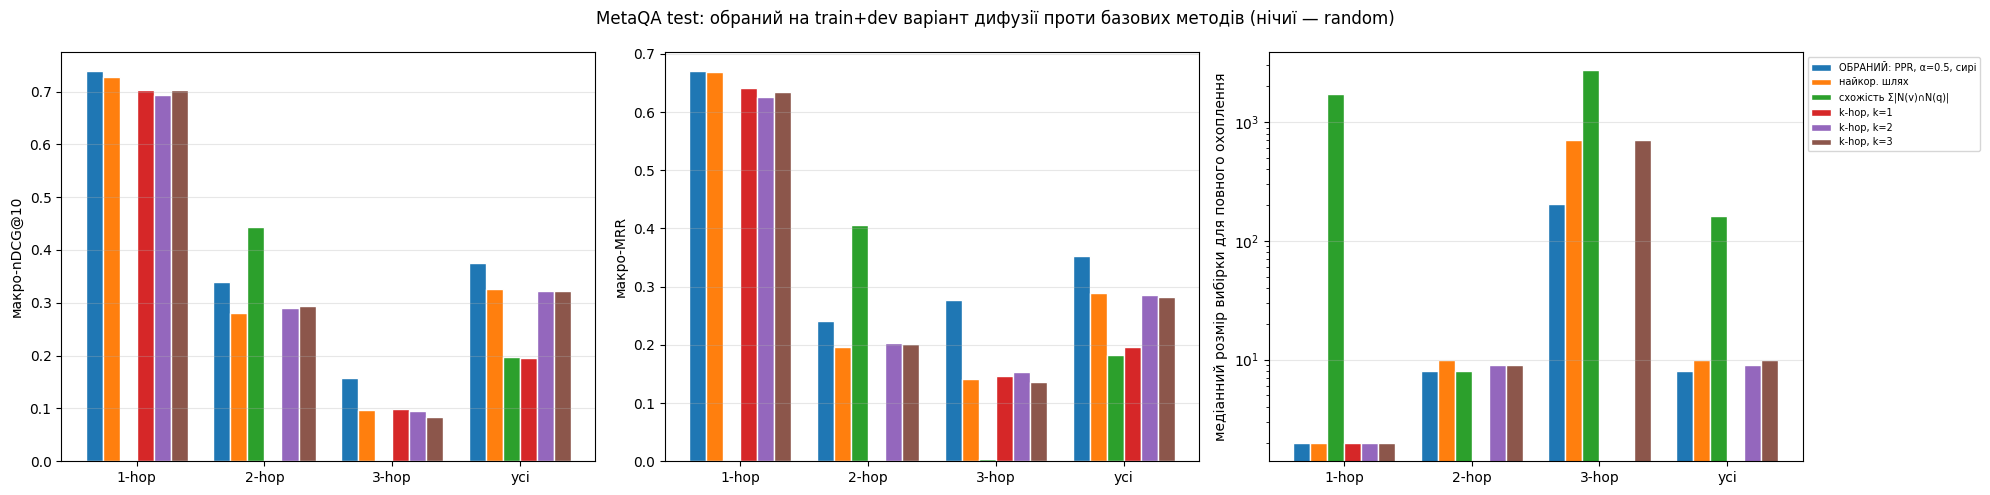

In [7]:
fig, axs = plt.subplots(1, 3, figsize=(20, 5))
order = [v for v in mq_tab["варіант"].unique()]
show = [v for v in order if v.startswith("ОБРАНИЙ") or "[random]" in v]
for ax, col, lab in zip(axs, ("nDCG@10", "RR", "охоплення_медіана"),
                        ("макро-nDCG@10", "макро-MRR", "медіанний розмір вибірки для повного охоплення")):
    w = 0.8 / len(show)
    for i, v in enumerate(show):
        y = mq_tab[mq_tab["варіант"] == v].set_index("hop")[col].reindex([1, 2, 3, "усі"])
        ax.bar(np.arange(4) + i * w, y, w, label=v.replace(" [random]", ""), color=f"C{i}", edgecolor="white")
    ax.set_xticks(np.arange(4) + 0.4 - w / 2); ax.set_xticklabels(["1-hop", "2-hop", "3-hop", "усі"])
    ax.set_ylabel(lab); ax.grid(alpha=0.3, axis="y")
    if col == "охоплення_медіана": ax.set_yscale("log")
axs[2].legend(fontsize=7, loc="upper left", bbox_to_anchor=(1.0, 1.0))
fig.suptitle("MetaQA test: обраний на train+dev варіант дифузії проти базових методів (нічиї — random)")
plt.tight_layout(); plt.savefig(FIG / "06_metaqa_za_hop.png", dpi=200); plt.show()

### Однаковий бюджет з k-hop (головне для диплома)

Для кожного test-питання і k = 1, 2, 3 беремо N = розмір k-околу вузла запиту. Питання таке: якщо передати LLM стільки ж вузлів, скільки дає GraphRAG з k кроками, у кого більше правильних відповідей? Окремо рахуємо питання, де k-околу зовсім не досить (жодної відповіді в ньому), а дифузія з тим самим N знаходить хоча б одну.

,hop,k,N_медіана,повнота_khop,повнота_дифузії,частка_khop_0_дифузія_знаходить,частка_khop_неповний_дифузія_повна,частка_дифузія_гірша,питань
0,1,1,4.000,1.000,0.999,0.000,0.000,0.007,427
1,1,2,40.000,1.000,1.000,0.000,0.000,0.000,427
2,1,3,336.000,1.000,1.000,0.000,0.000,0.000,427
3,2,1,1.000,0.000,0.001,0.004,0.000,0.000,832
4,2,2,14.000,1.000,0.997,0.000,0.000,0.017,832
5,2,3,195.000,1.000,1.000,0.000,0.000,0.000,832
6,3,1,9.000,0.131,0.131,0.000,0.000,0.000,380
7,3,2,180.000,0.133,0.531,0.387,0.263,0.000,380
8,3,3,1233.000,1.000,0.995,0.000,0.000,0.066,380


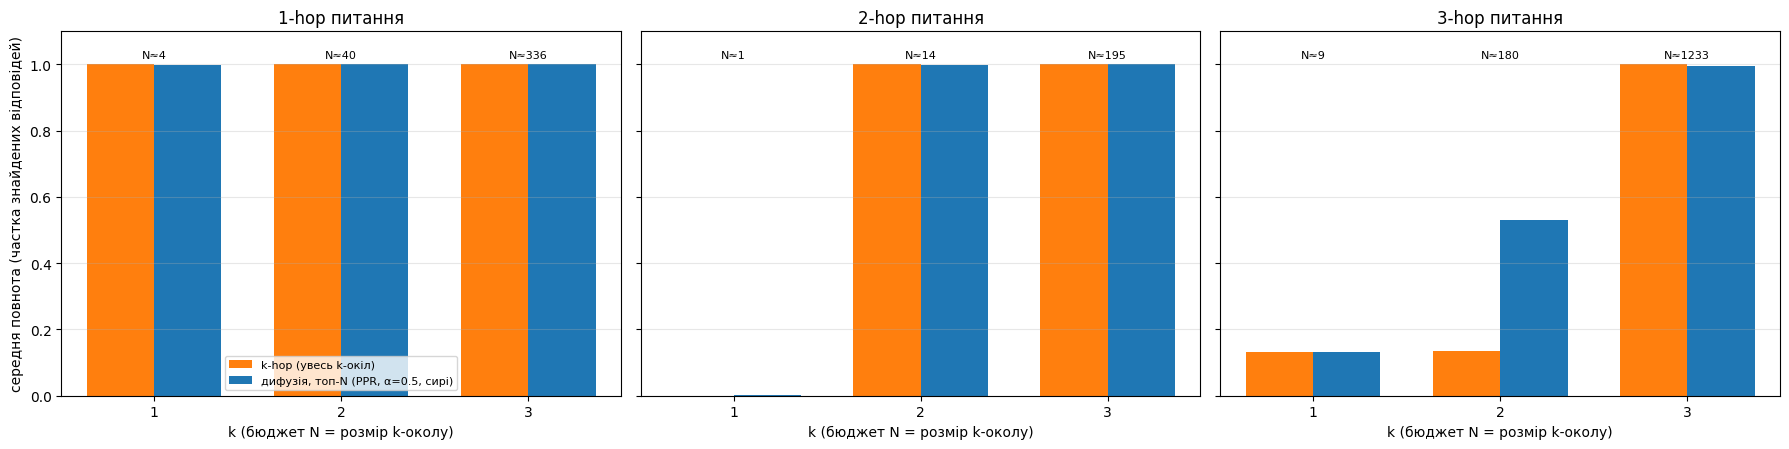

In [8]:
b = test_bud.copy()
b["khop_нуль_дифузія_знаходить"] = (b["повнота_khop"] == 0) & (b["повнота_дифузії"] > 0)
b["khop_неповний_дифузія_повна"] = (b["повнота_khop"] < 1) & (b["повнота_дифузії"] == 1)
b["дифузія_гірша"] = b["повнота_дифузії"] < b["повнота_khop"]
bud = b.groupby(["hop", "k"]).agg(N_медіана=("N", "median"), повнота_khop=("повнота_khop", "mean"),
                                  повнота_дифузії=("повнота_дифузії", "mean"),
                                  частка_khop_0_дифузія_знаходить=("khop_нуль_дифузія_знаходить", "mean"),
                                  частка_khop_неповний_дифузія_повна=("khop_неповний_дифузія_повна", "mean"),
                                  частка_дифузія_гірша=("дифузія_гірша", "mean"), питань=("N", "size")).reset_index()
bud.to_csv(RES / "06_metaqa_byudzhet_khop.csv", index=False)
display(bud)

fig, axs = plt.subplots(1, 3, figsize=(18, 4.6), sharey=True)
for ax, h in zip(axs, (1, 2, 3)):
    sub = bud[bud["hop"] == h]
    ax.bar(sub["k"] - 0.18, sub["повнота_khop"], 0.36, label="k-hop (увесь k-окіл)", color="C1")
    ax.bar(sub["k"] + 0.18, sub["повнота_дифузії"], 0.36, label=f"дифузія, топ-N ({MQ_CHOICE[0]}, {MQ_CHOICE[1]})", color="C0")
    for _, r in sub.iterrows():
        ax.text(r["k"], 1.02, f"N≈{r['N_медіана']:.0f}", ha="center", fontsize=8)
    ax.set_xticks([1, 2, 3]); ax.set_xlabel("k (бюджет N = розмір k-околу)"); ax.set_title(f"{h}-hop питання")
    ax.set_ylim(0, 1.1); ax.grid(alpha=0.3, axis="y")
axs[0].set_ylabel("середня повнота (частка знайдених відповідей)"); axs[0].legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "06_metaqa_byudzhet_khop.png", dpi=200); plt.show()

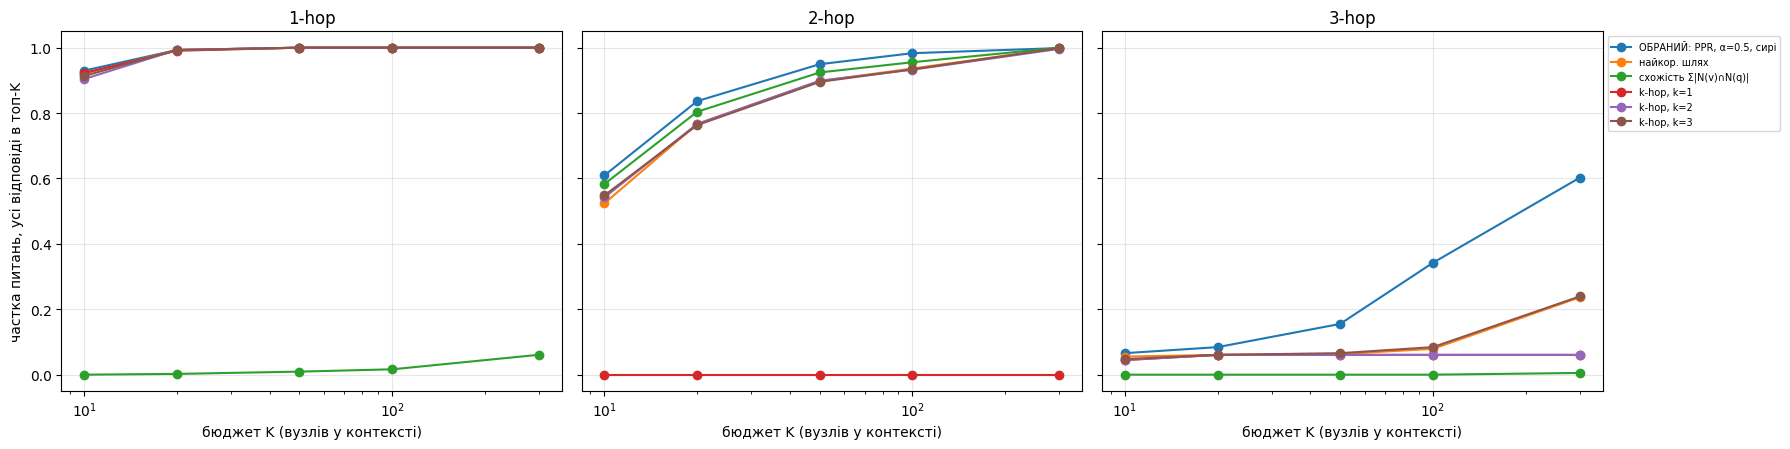

Додатково — фільтр за типом відповіді (макро-nDCG@10):


/tmp/ipykernel_102942/2961913997.py:19: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  ft = flt.groupby(["метод", "фільтр", "hop"]).apply(lambda d: d.groupby("qtype")["nDCG@10"].mean().mean()).unstack("hop")


hop                              1     2     3
метод                 фільтр                  
PPR, α=0.5            ні     0.738 0.340 0.158
                      так    0.989 0.932 0.727
k-hop, k=1            ні     0.703 0.000 0.098
k-hop, k=2            ні     0.693 0.290 0.095
k-hop, k=3            ні     0.703 0.294 0.084
найкор. шлях          ні     0.728 0.280 0.097
                      так    0.985 0.852 0.475
схожість Σ|N(v)∩N(q)| ні     0.000 0.443 0.001

In [9]:
# Повне охоплення в межах бюджету K і додатковий фільтр за типом відповіді
rows = []
for K in (10, 20, 50, 100, 300):
    for v in show:
        sub = main[main["варіант_повний"] == v]
        for h in (1, 2, 3):
            rows.append(dict(K=K, варіант=v.replace(" [random]", ""), hop=h, частка_охоплених=(sub[sub["hop"] == h]["coverage"] <= K).mean()))
cb = pd.DataFrame(rows); cb.to_csv(RES / "06_metaqa_okhoplennya_budzhet.csv", index=False)
fig, axs = plt.subplots(1, 3, figsize=(18, 4.6), sharey=True)
for ax, h in zip(axs, (1, 2, 3)):
    for i, v in enumerate(cb["варіант"].unique()):
        s0 = cb[(cb["варіант"] == v) & (cb["hop"] == h)]
        ax.plot(s0["K"], s0["частка_охоплених"], "o-", color=f"C{i}", label=v)
    ax.set_xscale("log"); ax.set_xlabel("бюджет K (вузлів у контексті)"); ax.set_title(f"{h}-hop"); ax.grid(alpha=0.3)
axs[0].set_ylabel("частка питань, усі відповіді в топ-K"); axs[2].legend(fontsize=7, loc="upper left", bbox_to_anchor=(1.0, 1.0))
plt.tight_layout(); plt.savefig(FIG / "06_metaqa_okhoplennya_budzhet.png", dpi=200); plt.show()

flt = test_res[test_res["нічиї"] == "random"]
ft = flt.groupby(["метод", "фільтр", "hop"]).apply(lambda d: d.groupby("qtype")["nDCG@10"].mean().mean()).unstack("hop")
ft.to_csv(RES / "06_metaqa_filtr_typu.csv")
print("Додатково — фільтр за типом відповіді (макро-nDCG@10):"); display(ft)

### Чому на MetaQA найкращі сирі оцінки

На налаштуванні всі нормування і сценарії ваг поступилися сирим оцінкам. Гіпотеза: у частини qtype відповіді — самі хаби (жанр, рік, мова), і нормування їх штрафує. Перевіряємо на окремій вибірці test (до 6 питань на qtype, seed = 5): nDCG@10 для PPR (α = 0.5) з сирими оцінками, π/d і IDF (β = 0.5) за типом відповіді разом із медіанним степенем відповідей.

In [2]:
from reldiff.api import rank as _rank
from reldiff import metrics as _M
_g, _q, _ = MQ.load_processed("../data/metaqa", 500, 0)
_edges = pd.read_csv("../data/metaqa/processed/movies500_seed0/subgraph_edges.csv", dtype=str, keep_default_na=False)
_deg = dict(_g.degree())
_h = nx.MultiGraph(); _h.add_nodes_from(_g.nodes(data=True))
for s_, r_, o_ in _edges.itertuples(index=False, name=None):
    _h.add_edge(s_, o_, type=r_, weight=_deg[o_] ** -0.5)
_qq = _q[(_q["split"] == "test") & ~_q["qtype"].isin({"movie_to_imdbvotes", "movie_to_imdbrating"})]
_r = np.random.default_rng(5)
_qq = pd.concat([d.iloc[_r.choice(len(d), min(6, len(d)), replace=False)] for _, d in _qq.groupby("qtype")])
_qq["тип_відповіді"] = _qq["qtype"].str.split("_to_").str[-1]
_rows = []
for p in _qq.itertuples():
    rel = set(p.answers) - {p.topic}
    if not rel: continue
    for nm, gg, kw in (("сирі", _g, {}), ("π/d", _g, dict(normalize="degree")), ("IDF β=0.5", _h, {})):
        s = _rank(gg, p.topic, alpha=0.5, **kw)
        _rows.append(dict(тип=p.тип_відповіді, варіант=nm, nDCG10=_M.ndcg_at_k(s, rel, 10, seeds=[p.topic]),
                          мед_степінь_відповіді=np.median([_deg[a] for a in rel])))
_d = pd.DataFrame(_rows)
by_type = _d.pivot_table(index="тип", columns="варіант", values="nDCG10").join(_d.groupby("тип")["мед_степінь_відповіді"].median())
by_type["питань"] = _d[_d["варіант"] == "сирі"].groupby("тип").size()
by_type = by_type.sort_values("мед_степінь_відповіді", ascending=False)
by_type.to_csv(RES / "06_metaqa_typ_vidpovidi.csv")
display(by_type)

,IDF β=0.5,π/d,сирі,мед_степінь_відповіді,питань
тип,,,,,
genre,0.102,0.034,0.454,132.250,42
year,0.135,0.162,0.229,13.750,42
language,0.152,0.152,0.195,11.250,36
movie,0.608,0.611,0.592,10.750,42
tags,0.482,0.485,0.442,4.250,6
director,0.365,0.336,0.340,2.000,36
actor,0.379,0.379,0.355,2.000,36
writer,0.397,0.350,0.379,1.500,36


### Чому схожість Σ|N(v) ∩ N(q)| слабка на MetaQA

На дводольному графі спільні сусіди є лише у вузлів тієї ж частки, тобто на парній відстані від запиту. Тому для всіх вузлів на непарній відстані Σ|N(v) ∩ N(q)| = 0. Відповіді 1-hop і 3-hop лежать на непарній відстані (людина → фільм, фільм → людина → фільм → атрибут). Перевіряємо: яка частка відповідей має нульову оцінку цього методу залежно від парності відстані.

In [10]:
rows = []
for topic, grp in TEST.groupby("topic", sort=False):
    dist = nx.single_source_shortest_path_length(g, topic)
    cn = rank(g, topic, "common_neighbors")
    for qq in grp.itertuples():
        for a in set(qq.answers) - {topic}:
            d = dist.get(a, np.inf)
            rows.append(dict(hop=qq.hop, парність=("непарна" if d % 2 == 1 else "парна") if np.isfinite(d) else "недосяжна",
                             нуль=cn[a] == 0))
cnz = pd.DataFrame(rows)
display(cnz.groupby(["hop", "парність"]).agg(відповідей=("нуль", "size"), частка_з_нульовою_оцінкою=("нуль", "mean")))

відповідей  частка_з_нульовою_оцінкою
hop парність                                       
1   непарна          781                      0.997
2   парна           2891                      0.000
3   непарна         3976                      1.000
    парна              9                      0.000

## Висновки

Головне порівняння всюди — з **випадковим** розбиттям нічиїх базових методів. Оптимістична межа на практиці недосяжна, бо вимагає знати відповідь заздалегідь, тож її наводимо як додаткову. Варіант дифузії обрано на окремих даних: на SBM — на графах з іншим seed, на MetaQA — на train+dev.

1. **SBM: дифузія виграє найбільше в зоні переходу, де спільноти ще виявні, але вже розмиті.** Обраний варіант — теплове ядро (t = 7, π/√d). Порівняння з найкоротшим шляхом:

   | p_out | P@10, дифузія | P@10, найкоротший шлях (random) | nDCG@50, дифузія | nDCG@50, найкоротший шлях |
   |---|---|---|---|---|
   | 0.001 | 0.982 | 0.890 | 0.991 | 0.844 |
   | 0.005 | 0.896 | 0.760 | 0.899 | 0.613 |
   | 0.0075 | 0.826 | 0.620 | 0.775 | 0.493 |
   | 0.01 | 0.692 | 0.528 | 0.585 | 0.417 |
   | 0.02 | 0.434 | 0.400 | 0.362 | 0.325 |

   - Розмір вибірки для повного охоплення спільноти при p_out = 0.001 становить 201 вузол, тобто майже ідеальні 199, проти 784 у найкоротшого шляху.
   - **Контроль p_out = 0.02** дає P@10 близько 0.4 для всіх методів, а не 0.2, як при випадковому ранжуванні. Частка своїх серед сусідів (10 / (10 + 16) ≈ 0.38) лишається вищою за частку спільноти в графі (0.2), тож локальний сигнал є навіть тут. Переваги дифузії при цьому майже немає.
   - **Однаковий бюджет:** при k = 2 повнота топ-N дифузії 0.49–0.68 проти 0.41–0.49 у k-околу (p_out ≤ 0.01). Виняток — контроль: 0.568 проти 0.593.
2. **MetaQA: обраний на train+dev варіант — PPR з α = 0.5 і сирими оцінками.** На test він другий з 36 (0.371 проти найкращих 0.372), тож вибір на train+dev добре переноситься і майже не завищений.

   | hop | макро-nDCG@10, дифузія | макро-nDCG@10, найкоротший шлях (random) |
   |---|---|---|
   | 1 | 0.738 | 0.728 |
   | 2 | 0.340 | 0.280 |
   | 3 | 0.158 | 0.097 |
   | усі | 0.375 | 0.326 |

   - MRR для 3-hop: 0.278 проти 0.141.
   - Медіанний розмір вибірки для повного охоплення відповідей 3-hop — 203.5 вузла проти 702.5.
   - Ідеальне (недосяжне) розбиття нічиїх дало б найкоротшому шляху 0.553 загалом.
3. **Однаковий бюджет з k-hop — головне для диплома.**
   - Для 1-hop обидва методи знаходять усі відповіді при будь-якому k (N ≈ 4, 40, 336).
   - Для 2-hop при k = 2 (N ≈ 14) повнота k-hop 1.000, дифузії 0.997: дифузія гірша в 1.7% питань.
   - **Для 3-hop при k = 2 (N ≈ 180) повнота k-hop лише 0.133, а дифузії з тим самим бюджетом 0.531.** У 38.7% 3-hop питань k-окіл не містить жодної відповіді, а топ-N дифузії містить хоча б одну. У 26.3% питань дифузія знаходить усі відповіді, а k-окіл — ні.
   - При k = 3 k-окіл займає ≈ 1233 вузли (42% графа), і обидва методи мають повноту ≈ 1.
   - За бюджету в 300 вузлів дифузія повністю охоплює відповіді в 60% 3-hop питань, а найкоротший шлях і k-hop (k = 3) — у 24%.
   - Отже, дифузія виграє тоді, коли відповіді лежать за межами k-околу, який вміщується в бюджет контексту, тобто в багатоступінчастих запитах.
4. **Нормування і ваги для запитів з одним вузлом шкодять.**
   - На train+dev макро-nDCG@10 становить: сирі оцінки 0.32–0.365, «змістовні важчі» 0.30–0.34, IDF 0.23–0.30, π/d 0.22–0.28.
   - Причина — тип відповіді. Для жанрів (медіанний степінь відповіді 132) nDCG@10 падає з 0.454 до 0.034 (π/d) і 0.102 (IDF). Для років і мов падіння менше. Для відповідей малого степеня (люди, теги, фільми) нормування дає +0.02–0.04.
   - Тобто нормування, корисне для мостів у п. 5, для запитів з відповіддю-хабом шкідливе. Вибирати його варто залежно від очікуваного типу відповіді, а це інформація з тексту питання, тобто задача диплома.
   - Фільтр за типом відповіді (додатково) піднімає макро-nDCG@10 дифузії до 0.989, 0.932 і 0.727 для 1/2/3-hop. Найкоротший шлях із тим самим фільтром дає 0.985, 0.852 і 0.475.
5. **Схожість Σ|N(v) ∩ N(q)| слабка на MetaQA за побудовою, бо граф дводольний.**
   - Ненульові оцінки мають лише вузли на парній відстані. Тому 99.7% відповідей 1-hop і 100% відповідей 3-hop (непарна відстань) отримують нуль, а nDCG@10 становить 0.000 і 0.001.
   - Для 2-hop питань, де відповіді на парній відстані, цей метод навпаки найкращий: 0.443 проти 0.340 у дифузії.
   - На SBM (недводольний) він поводиться нормально: P@10 = 0.954 при p_out = 0.001.

**Коли дифузія виграє в простих способів, а коли ні.** Виграє, коли:
- відповіді далі, ніж дозволяє бюджет k-околу (3-hop);
- простий метод дає багато нічиїх (відстань);
- спільноти розмиті, але ще виявні.

Не виграє:
- у 1-hop питаннях, де k-hop з k = 1 практично ідеальний;
- у 2-hop питаннях з відповіддю на парній відстані, де краща Σ-схожість;
- коли структура не несе сигналу (контроль SBM).